In [31]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter
import pickle

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, run_psy
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


In [32]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):
    """
    Scale price using a linear trend on smoothed log-variance.
    """

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility (safe sqrt)
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol


### Import WTI and detrend series + linear trend of the volatility scaling

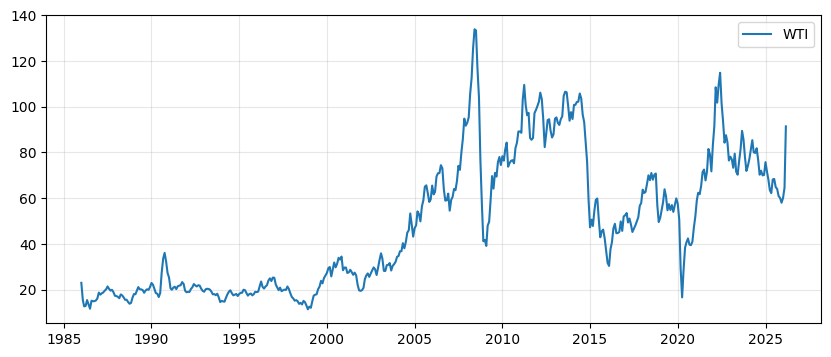

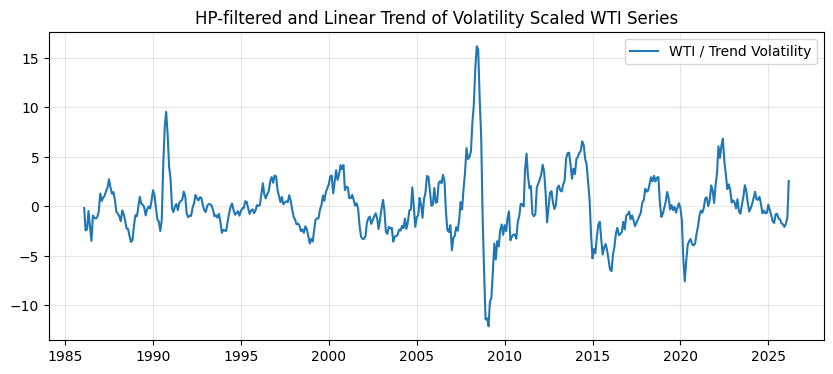

In [33]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
cycle, trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

df_wti["wti_cycle"] = cycle
df_wti["wti_trend"] = trend

# Compute differences and linear trend volatility estimation
wti_diff = (df_wti["wti_cycle"]).diff()
wti_vol = linear_vol_scale(wti_diff)

df_wti["wti_scaled_cycle"] = df_wti["wti_cycle"]/wti_vol


# -------------------------
# PLOTS
# -------------------------

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_wti.index, df_wti["MCOILWTICO"], label="WTI")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(df_wti["wti_scaled_cycle"], label="WTI / Trend Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.title("HP-filtered and Linear Trend of Volatility Scaled WTI Series")
plt.show()

In [34]:
T = len(df_wti)
r0 = 0.01 + 1.8 / np.sqrt(T)
swindow0 = int(np.floor(r0 * T))
yr = 2
Tb = 12 * yr + swindow0 - 1

psy = run_psy(
    y=df_wti["MCOILWTICO"].values,
    dates=df_wti.index,
    IC=2,
    adflag=6,
    Tb = Tb,
    nboot=1999)


with open("psy_wti.pkl", "wb") as f:
    pickle.dump(psy, f)

### Extract Data for Exogeous Variables

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_74558/389981700.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


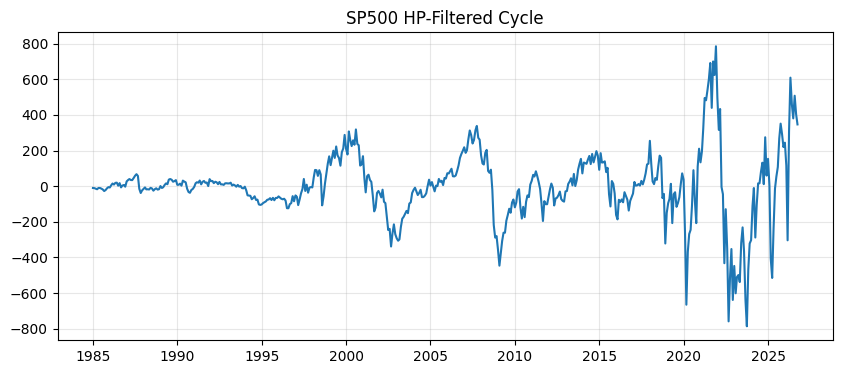

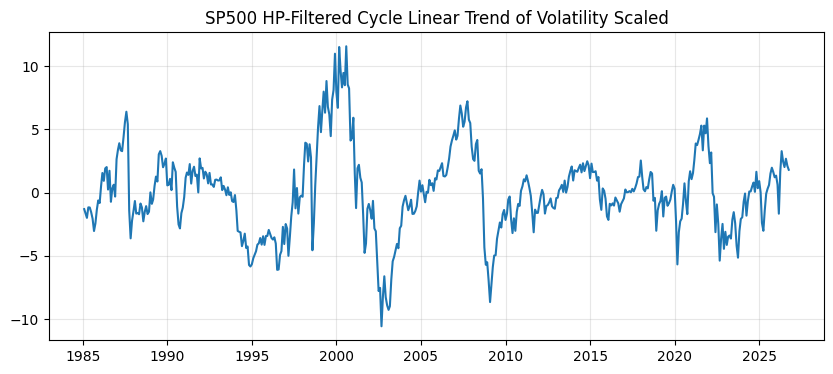

In [35]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter
sp500_cycle, trend = hpfilter(sp500_original, lamb=129600)

sp500_diff = (sp500_cycle).diff().dropna()
sp500_sigma = linear_vol_scale(sp500_diff)

sp500= sp500_cycle/sp500_sigma


plt.figure(figsize=(10,4))
plt.plot(sp500_cycle)
plt.title("SP500 HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_74558/589057072.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


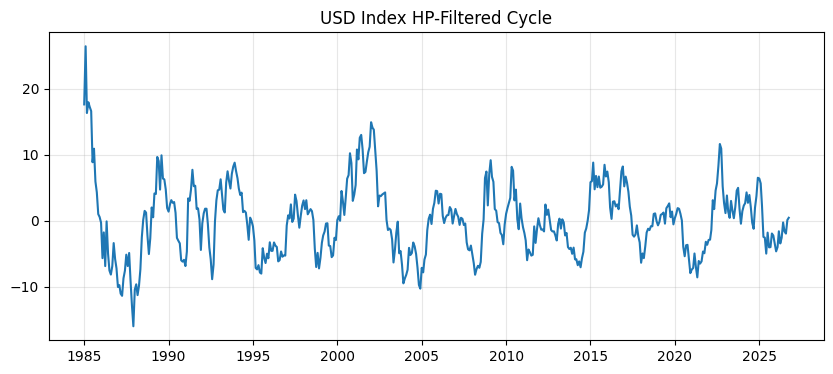

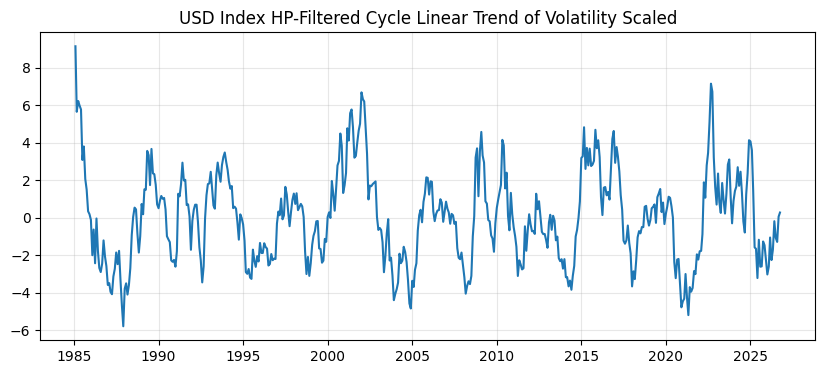

In [36]:
# -------------------------
# USD INDEX
# -------------------------
usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
usd_ind_original = usd_ind_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
usd_ind_cycle, trend = hpfilter(usd_ind_original, lamb=129600)

usd_ind_diff = (usd_ind_cycle).diff().dropna()
usd_ind_sigma = linear_vol_scale(usd_ind_diff)

usd_ind= usd_ind_cycle/usd_ind_sigma


plt.figure(figsize=(10,4))
plt.plot(usd_ind_cycle)
plt.title("USD Index HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(usd_ind)
plt.title("USD Index HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()


/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_74558/904516455.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


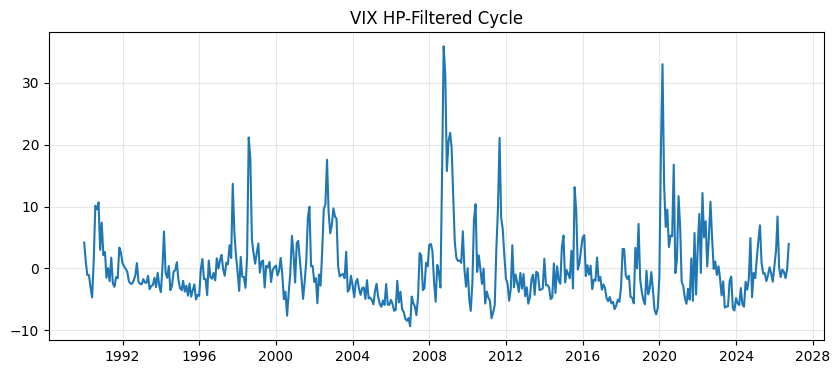

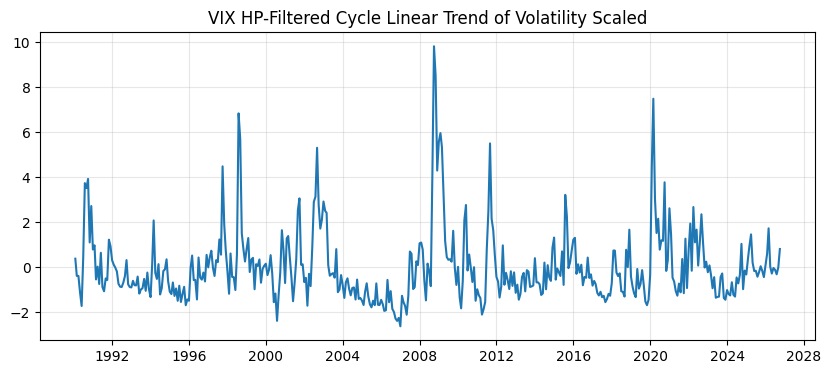

In [37]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
vix_cycle, trend = hpfilter(vix_original, lamb=129600)

vix_diff = (vix_cycle).diff().dropna()
vix_sigma = linear_vol_scale(vix_diff)

vix= vix_cycle/vix_sigma


plt.figure(figsize=(10,4))
plt.plot(vix_cycle)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(vix)
plt.title("VIX HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

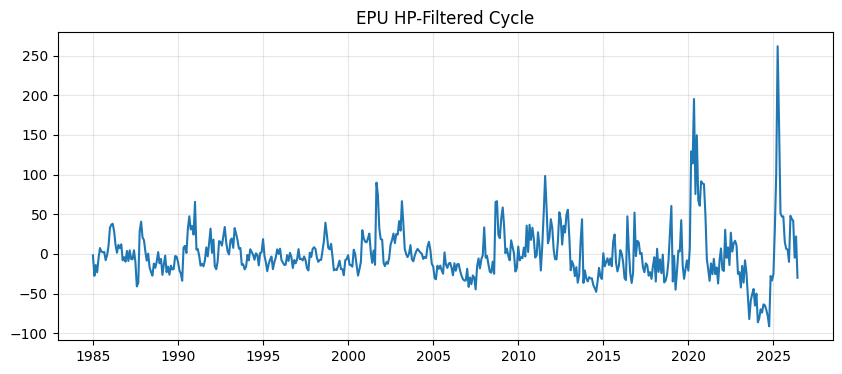

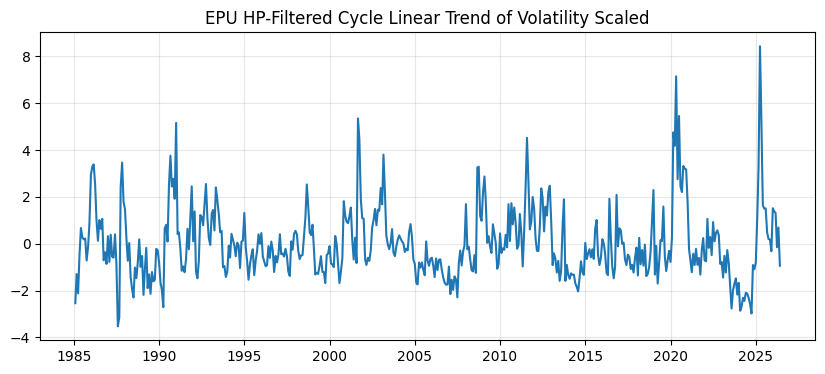

In [38]:
# -------------------------
# Economic Policy Uncertainty US
# -------------------------
df_epu = pd.read_csv("USEPUINDXM.csv", parse_dates=["observation_date"])
df_epu = df_epu.dropna().set_index("observation_date")


# HP filter
epu_cycle , trend = hpfilter(df_epu["USEPUINDXM"], lamb=129600)

epu_diff = (epu_cycle).diff().dropna()
epu_sigma = linear_vol_scale(epu_diff)

epu= epu_cycle/epu_sigma


plt.figure(figsize=(10,4))
plt.plot(epu_cycle)
plt.title("EPU HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(epu)
plt.title("EPU HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

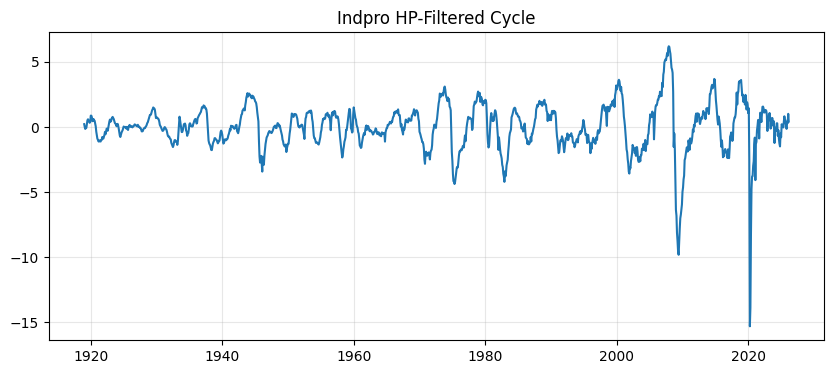

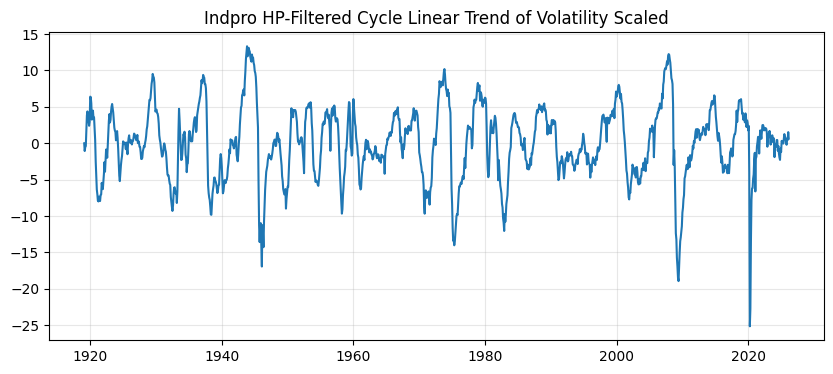

In [39]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter 
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

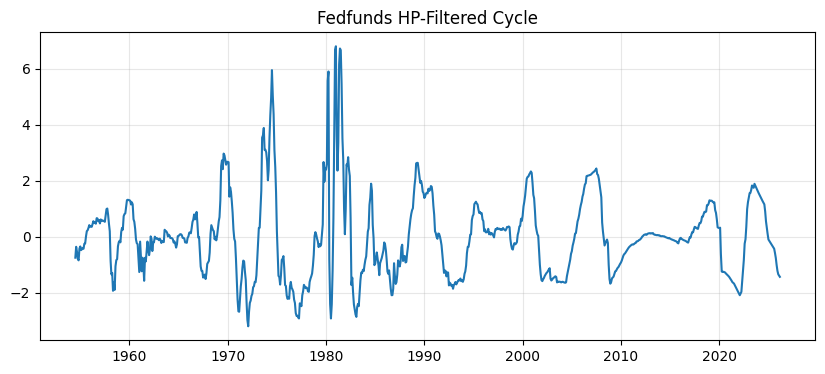

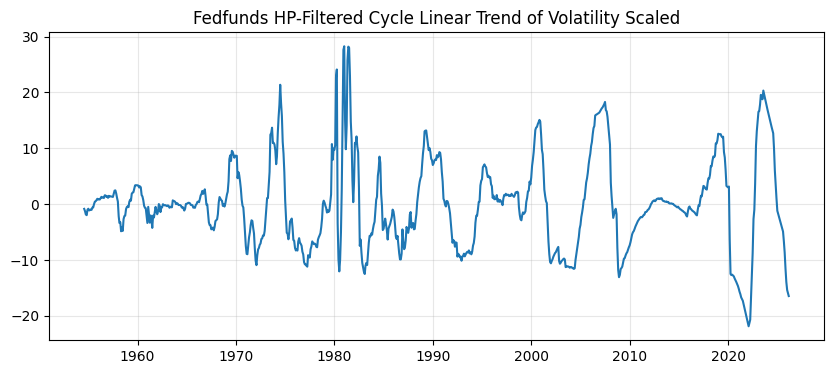

In [40]:
# -------------------------
# Fed Funds
# -------------------------
fedfunds_original = pd.read_csv("FEDFUNDS.csv", parse_dates=["observation_date"])
fedfunds_original = fedfunds_original.dropna().set_index("observation_date")

# -------------------------
# HP Filter 
# -------------------------
fedfunds_cycle, trend = hpfilter(fedfunds_original, lamb=129600)


fedfunds_diff = (fedfunds_cycle).diff().dropna()
fedfunds_sigma = linear_vol_scale(fedfunds_diff)

fedfunds = fedfunds_cycle/fedfunds_sigma


plt.figure(figsize=(10,4))
plt.plot(fedfunds_cycle)
plt.title("Fedfunds HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(fedfunds)
plt.title("Fedfunds HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

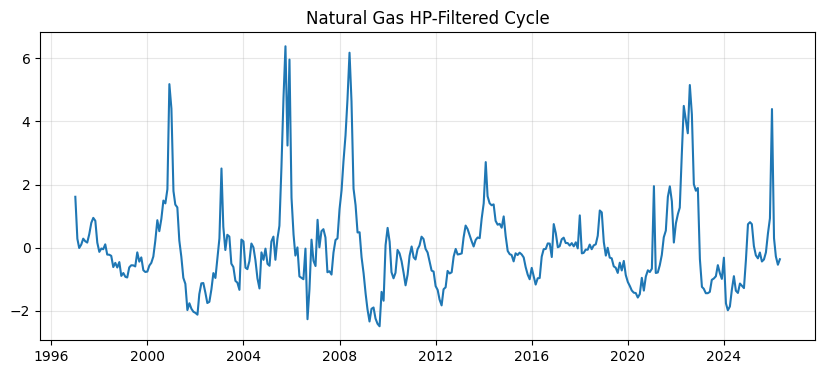

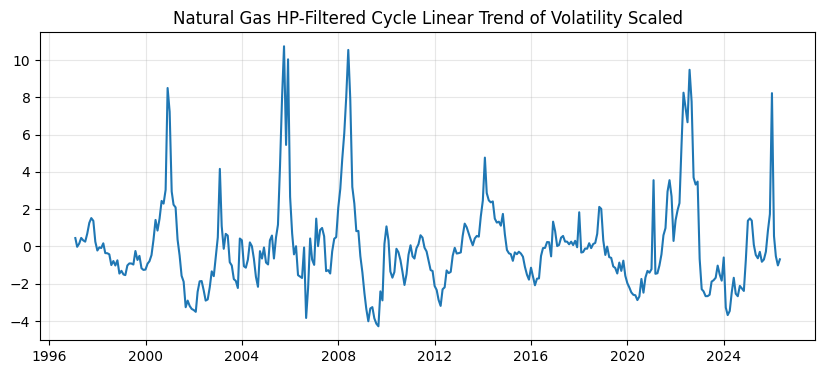

In [41]:
# -------------------------
# Natural Gas
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
ngas_cycle, ngas_trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

ngas_diff = (ngas_cycle).diff().dropna()
ngas_sigma = linear_vol_scale(ngas_diff)

ngas= ngas_cycle/ngas_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_cycle)
plt.title("Natural Gas HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas)
plt.title("Natural Gas HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

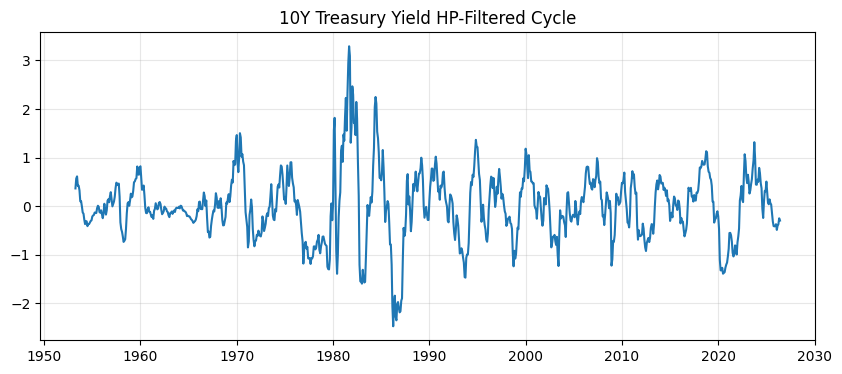

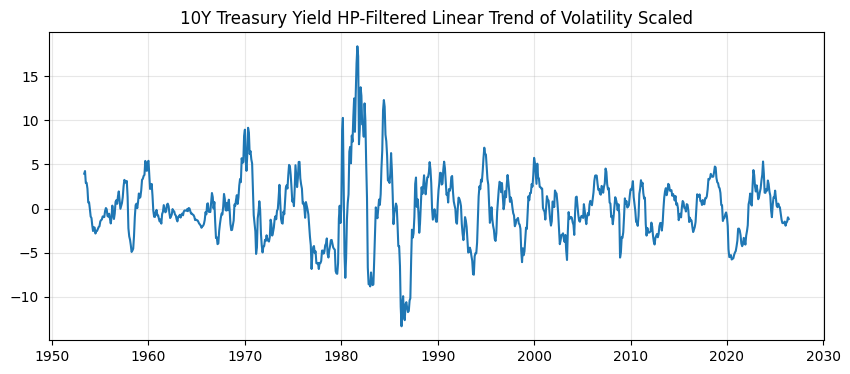

In [42]:
# -------------------------
# 10 Year Treasury Yield
# -------------------------
df_10y_treasury = pd.read_csv("GS10.csv", parse_dates=["observation_date"])
df_10y_treasury = df_10y_treasury.dropna().set_index("observation_date")


# HP filter
treasury_10y_cycle , trend = hpfilter(df_10y_treasury["GS10"], lamb=129600)

treasury_10y_diff = (treasury_10y_cycle).diff().dropna()
treasury_10y_sigma = linear_vol_scale(treasury_10y_diff)

treasury_10y= treasury_10y_cycle/treasury_10y_sigma


plt.figure(figsize=(10,4))
plt.plot(treasury_10y_cycle)
plt.title("10Y Treasury Yield HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(treasury_10y)
plt.title("10Y Treasury Yield HP-Filtered Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_74558/3610332454.py:4: DtypeWarning: Columns (2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499,500,501,502,503,504,505,506,507,508,509,510,511,512,513,514,515,516,517,518,519,520,521,522,523,524,525,526,527,528,529,530,531,532,533,534,535,536,537,538,539,540,541,542,543,544,545,546,547,548,549,550,551,552,553,554,555,556,557,558,559,560,561,562,563,564,565,566,567,568,569,570,571,572,573,574,575,576,577,578,579,580,581,582,583,584,585,586,587,588,589,590,591,592,593,594,595,596,597,598,599,600,601,602,603,604,605,606,607,608,609,610,611,612,613,614,615,616,617,618,619,620,621,622,623) have mixed types. Specify dtype op

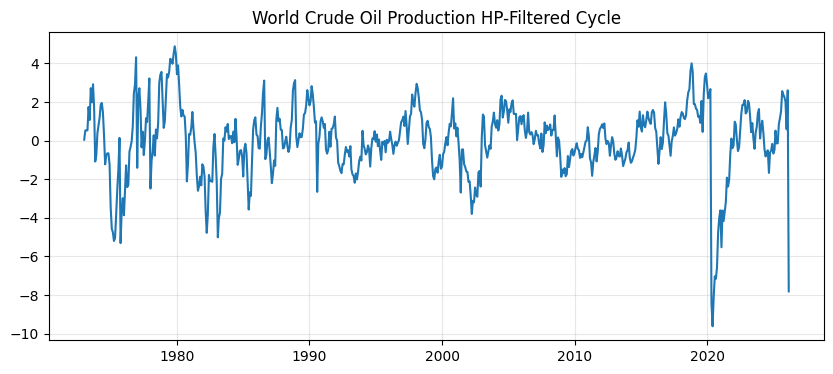

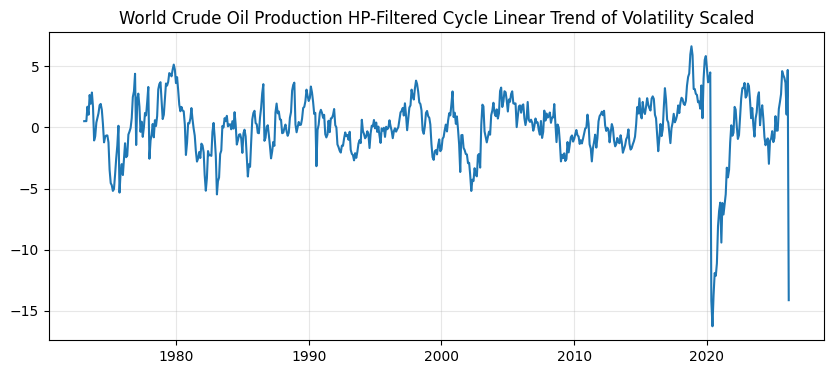

In [43]:
# -------------------------
# World Crude Oil Production
# -------------------------
df_oil = pd.read_csv(
    "World Crude Oil Production.csv",
    skiprows=1
)

# Select the World crude oil production row
world_crude = df_oil[
    df_oil["API"].str.contains("WORL", na=False) &
    df_oil.iloc[:,1].str.contains("Crude oil including lease condensate", na=False)
]


# Keep only the monthly data (drop metadata columns)
oil_series = world_crude.iloc[0, 2:]

# Convert the column names (YYYYMM) to dates
oil_series.index = pd.to_datetime(oil_series.index, format="%b %Y")

# Convert values to numeric
oil_series = pd.to_numeric(oil_series, errors="coerce").dropna()

# HP filter

oil_series=0.001*oil_series
world_oil_cycle, oil_trend = hpfilter(oil_series, lamb=129600)

world_oil_diff = (world_oil_cycle).diff().dropna()
world_oil_sigma = linear_vol_scale(world_oil_diff)

world_oil= world_oil_cycle/world_oil_sigma


plt.figure(figsize=(10,4))
plt.plot(world_oil_cycle)
plt.title("World Crude Oil Production HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(world_oil)
plt.title("World Crude Oil Production HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

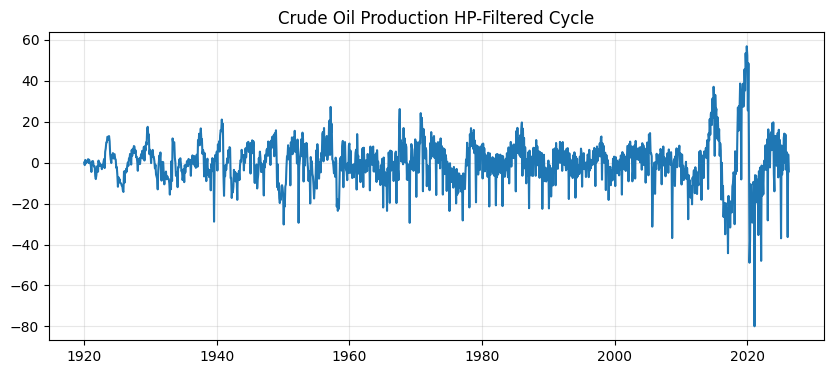

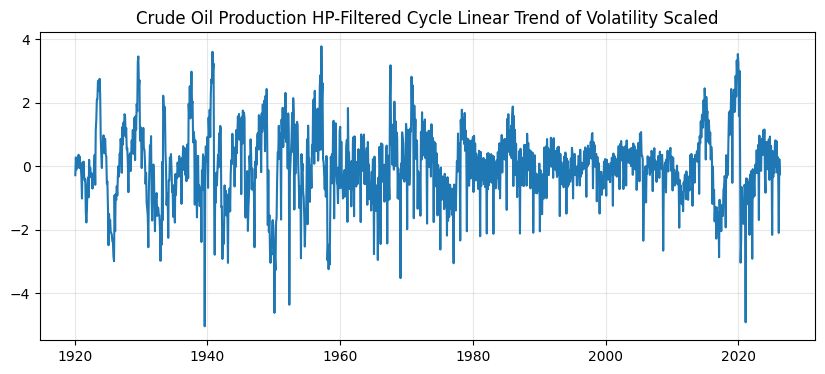

In [44]:
# -------------------------
# Crude Oil Production
# -------------------------

df_oil_prod = pd.read_excel(
    "Crude Oil US Production.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_oil_prod["Date"] = pd.to_datetime(
    df_oil_prod["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_oil_prod["Date"] = df_oil_prod["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_oil_prod = df_oil_prod.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_oil_prod=0.001*df_oil_prod
oil_prod_cycle, trend = hpfilter(
    df_oil_prod["U.S. Field Production of Crude Oil (Thousand Barrels)"],
    lamb=129600
)

oil_prod_diff = (oil_prod_cycle).diff().dropna()
oil_prod_sigma = linear_vol_scale(oil_prod_diff)

oil_prod= oil_prod_cycle/oil_prod_sigma


plt.figure(figsize=(10,4))
plt.plot(oil_prod_cycle)
plt.title("Crude Oil Production HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(oil_prod)
plt.title("Crude Oil Production HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

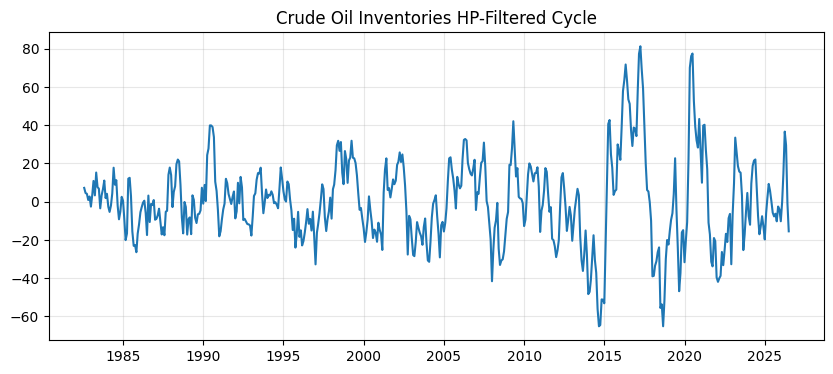

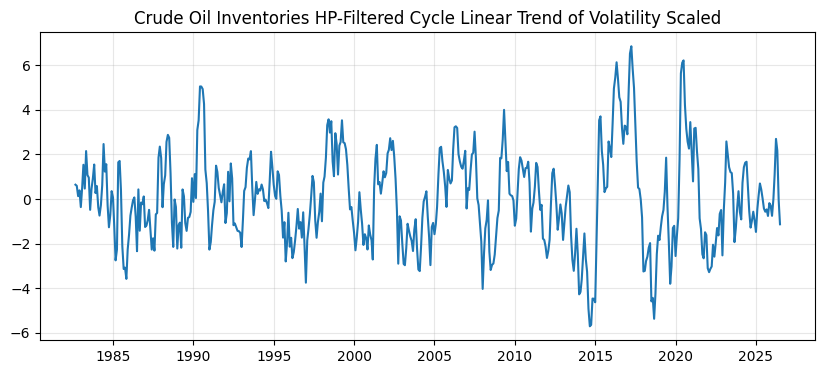

In [45]:
# -------------------------
# Crude Oil Inventories
# -------------------------

df_inv = pd.read_excel(
    "Crude Oil Inventories WEEKLY.xls",
    sheet_name="Data 1",      
    skiprows=2                
)

# Convert dates
df_inv["Date"] = pd.to_datetime(df_inv["Date"])

# Keep the first weekly observation of each month
df_inv = (
    df_inv.sort_values("Date")
          .groupby(df_inv["Date"].dt.to_period("M"), as_index=False)
          .first()
)

# Set dates to the first day of each month
df_inv["Date"] = df_inv["Date"].dt.to_period("M").dt.to_timestamp()

# Set index
df_inv = df_inv.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_inv=0.001*df_inv
crudeoil_inventory_cycle, crudeoil_inventory_trend = hpfilter(
    df_inv["Weekly U.S. Ending Stocks excluding SPR of Crude Oil  (Thousand Barrels)"],  
    lamb=129600
)

crudeoil_inventory_diff = (crudeoil_inventory_cycle).diff().dropna()
crudeoil_inventory_sigma = linear_vol_scale(crudeoil_inventory_diff)

crudeoil_inventory= crudeoil_inventory_cycle/crudeoil_inventory_sigma


plt.figure(figsize=(10,4))
plt.plot(crudeoil_inventory_cycle)
plt.title("Crude Oil Inventories HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(crudeoil_inventory)
plt.title("Crude Oil Inventories HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

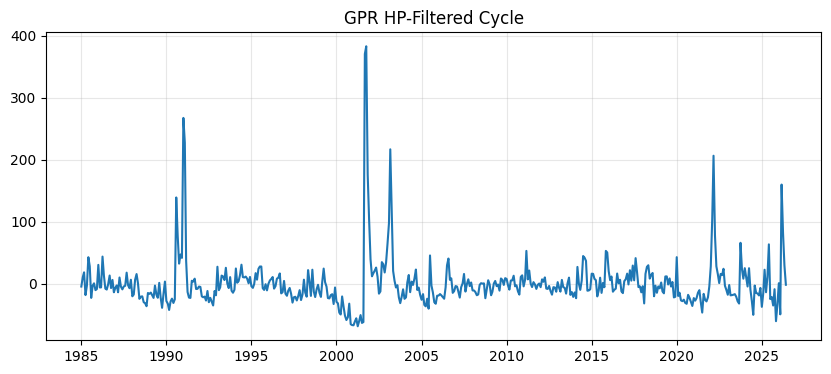

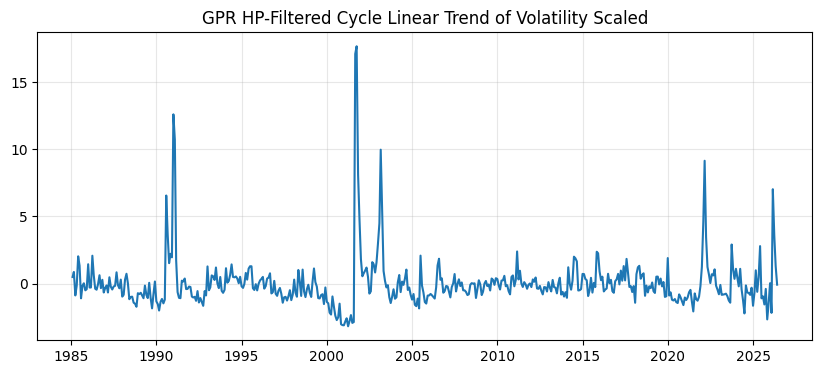

In [46]:
# -------------------------
# GPR
# -------------------------
df = pd.read_excel("GPR.xls", usecols=["month", "GPR"])

# Convert Month column to datetime
df["month"] = pd.to_datetime(df["month"])

# Set Month as index
df = df.set_index("month")

# Extract GPR series
gpr_original = df["GPR"].dropna()

# -------------------------
# HP Filter
# -------------------------
gpr_cycle, gpr_trend = hpfilter(gpr_original, lamb=129600)

gpr_diff = (gpr_cycle).diff().dropna()
gpr_sigma = linear_vol_scale(gpr_diff)

gpr = gpr_cycle/gpr_sigma


plt.figure(figsize=(10,4))
plt.plot(gpr_cycle)
plt.title("GPR HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(gpr)
plt.title("GPR HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [47]:
# Data and Parameters 
df = pd.concat(
    [
        df_wti["wti_scaled_cycle"], sp500, usd_ind, vix, epu, indpro, fedfunds, ngas_cycle, treasury_10y, oil_prod, world_oil_cycle, crudeoil_inventory, gpr
    ],
    axis=1
).dropna()

df.columns = ["wti_scaled_cycle", "sp500", "usd_ind", "vix", "epu", "indpro", "fedfunds", "ngas_cycle", "treasury_10y", "oil_prod", "world_oil_cycle", "crudeoil_inventory", "gpr"]
df = df.sort_index()

y = df["wti_scaled_cycle"].values
X = df[["sp500", "usd_ind", "vix", "epu", "indpro", "fedfunds", "ngas_cycle", "treasury_10y", "oil_prod", "world_oil_cycle",  "crudeoil_inventory", "gpr"]].values

var = ["sp500", "usd_ind", "vix", "epu", "indpro", "fedfunds", "ngas_cycle", "treasury_10y", "oil_prod", "world_oil_cycle", "crudeoil_inventory", "gpr"]



print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

t0=len(y)-1 # point to calculate predictive density


#Define Grid for all experiments
grid_min=-100
grid_max=100
ngrid=2000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)

#Parameters for effect of exogenous regressors on bimodality 
std=10
values=30

prominence = 0.01

y_limits=(-20, 20)

Aligned sample: 351 monthly observations
Date range: 1997-01-01 to 2026-03-01


----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -576.6248507514458

Estimated parameters:
phi             =     0.7782 (0.0384)
psi             =     0.3533 (0.0654)
sigma           =     0.5973 (0.0423)

Hessian condition number:
8.514214067481845

Eigenvalues of Hessian:
[1646.7140733   193.40764283  568.98764029]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -576.624851
AIC:            1159.249702
BIC:            1170.814917
R^2:            0.871883

Autocorrelation tests (standardized residuals):
  n       = 349
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 6.372993, p-value = 0.011587
    lag  5: statistic = 20.126994, p-value = 0.00118297
    lag 10: statistic = 24.221061, p-value = 0.00703476
    lag 20: statistic = 35.852900, p-value = 0.0160048

Autocorrelation tests (squared standardized residuals):
  n       = 349
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 45.946580, p-value = 1.21522e-11
    lag  5: sta

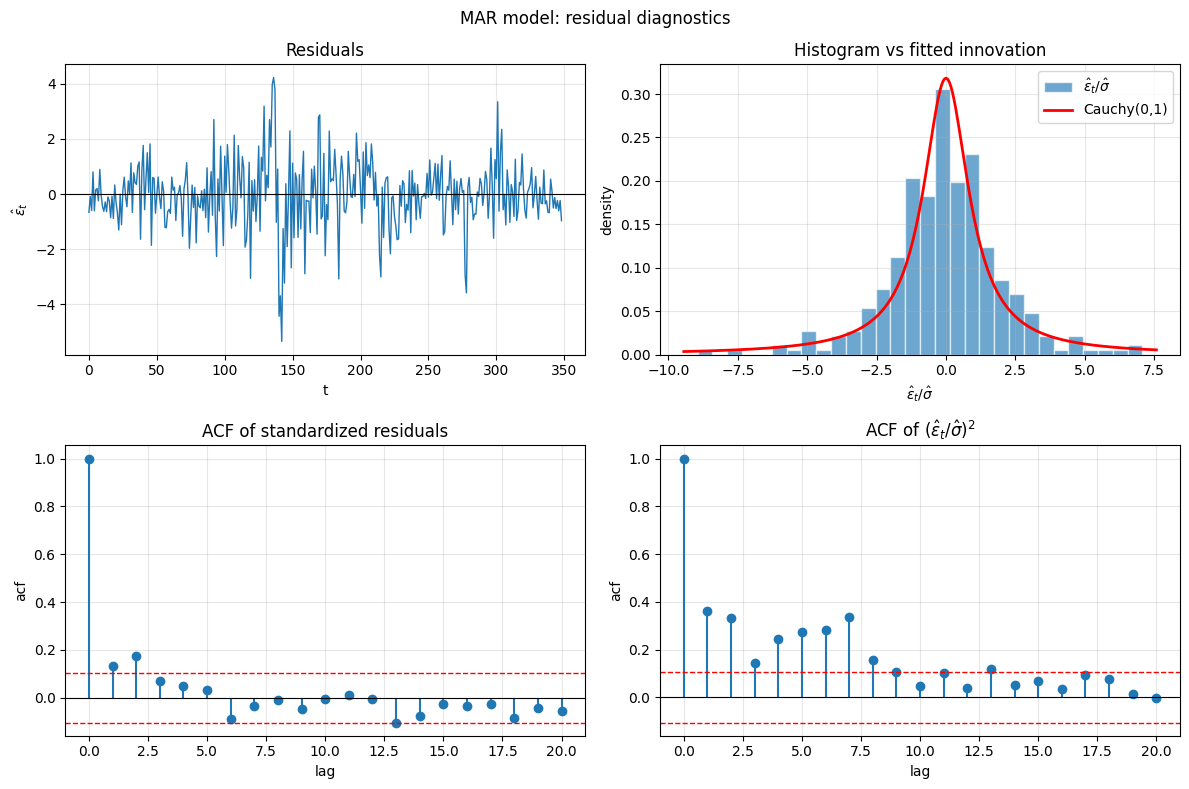

In [48]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

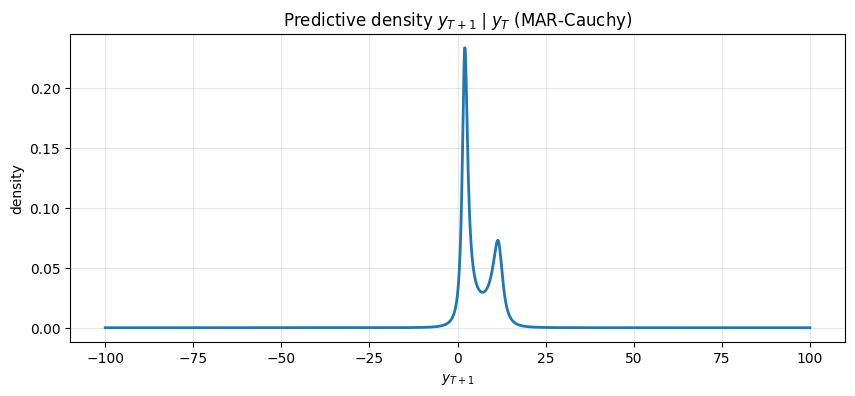

In [49]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

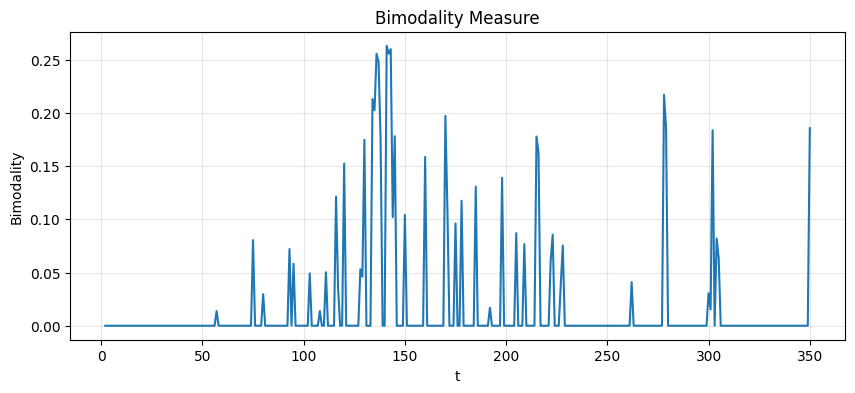

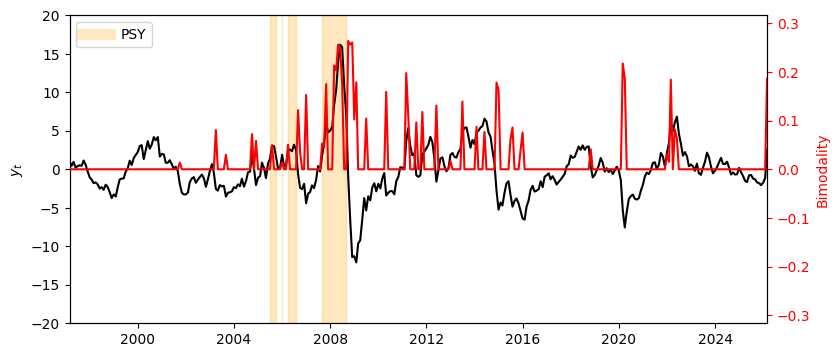

In [50]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -536.855927463386

Estimated parameters:
phi             =     0.3988 (0.0421)
psi             =     0.5349 (0.0374)
beta_sp500      =    -0.0414 (0.0183)
beta_usd_ind    =    -0.0201 (0.0234)
beta_vix        =    -0.0648 (0.0382)
beta_epu        =    -0.0517 (0.0351)
beta_indpro     =     0.0737 (0.0209)
beta_fedfunds   =     0.0062 (0.0085)
beta_ngas_cycle =     0.2904 (0.0622)
beta_treasury_10y =     0.0745 (0.0270)
beta_oil_prod   =     0.0487 (0.0588)
beta_world_oil_cycle =    -0.1884 (0.0302)
beta_crudeoil_inventory =    -0.1092 (0.0257)
beta_gpr        =     0.0350 (0.0205)
sigma           =     0.5252 (0.0378)

Hessian condition number:
275.2411818829451

Eigenvalues of Hessian:
[47228.76509053 12303.73788568  5642.40897469  4095.75095926
  2916.04568746  2549.00021728  2012.76716625  1440.5479732
   171.59047482   392.55741637   337.77782711  1087.72018542
   940.06576723   639.30143636   717.35151813]

MLE diagnostics

--- MARX model

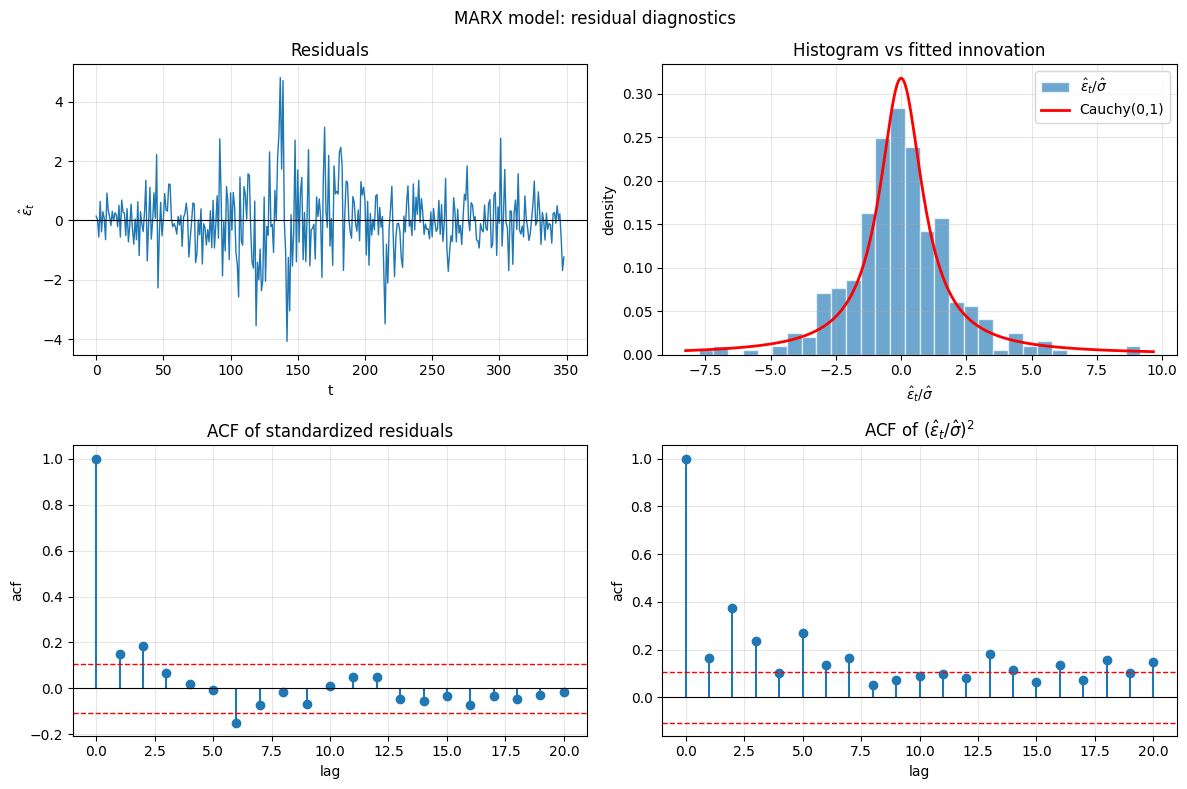

In [51]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_sp500", "beta_usd_ind", "beta_vix", "beta_epu", "beta_indpro", "beta_fedfunds", "beta_ngas_cycle", "beta_treasury_10y", "beta_oil_prod","beta_world_oil_cycle", "beta_crudeoil_inventory", "beta_gpr", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

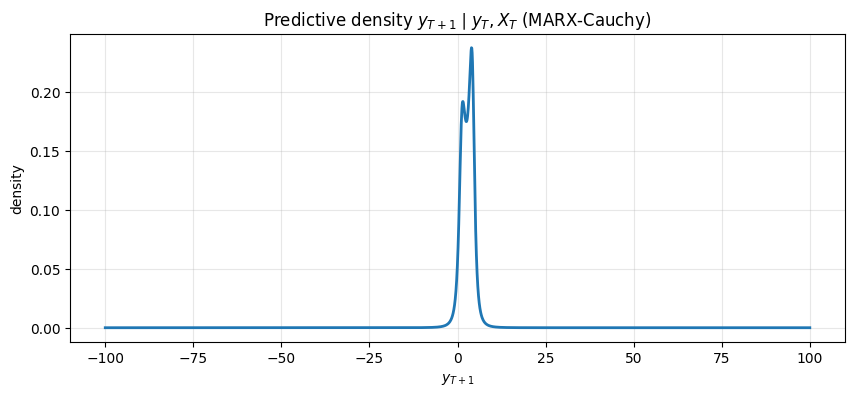

In [52]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

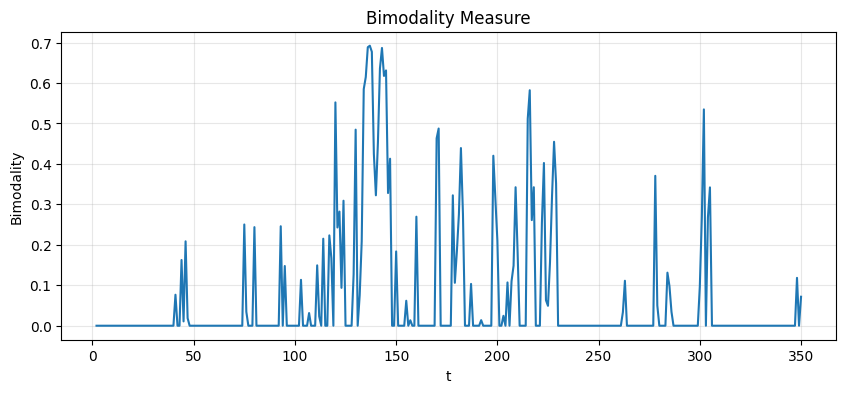

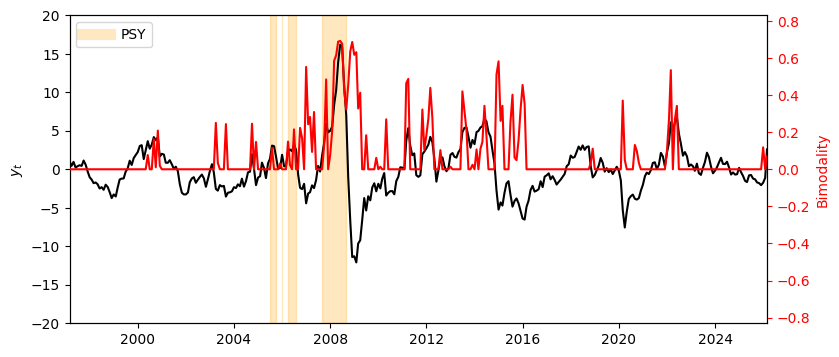

In [53]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -541.4223907469773

Estimated parameters:
phi             =     0.8352 (0.0350)
psi             =     0.3251 (0.0603)
sigma           =     0.8783 (0.0610)
nu              =     4.0097 (0.9321)

Hessian condition number:
1293.998041565017

Eigenvalues of Hessian:
[1.48633344e+03 5.13121637e+02 2.40951996e+02 1.14863654e+00]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -541.422391
AIC:            1090.844781
BIC:            1106.265069
R^2:            0.873745

Autocorrelation tests (standardized residuals):
  n       = 349
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 3.332450, p-value = 0.0679256
    lag  5: statistic = 9.957766, p-value = 0.0764408
    lag 10: statistic = 16.888006, p-value = 0.0768791
    lag 20: statistic = 26.054779, p-value = 0.16401

Autocorrelation tests (squared standardized residuals):
  n       = 349
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statisti

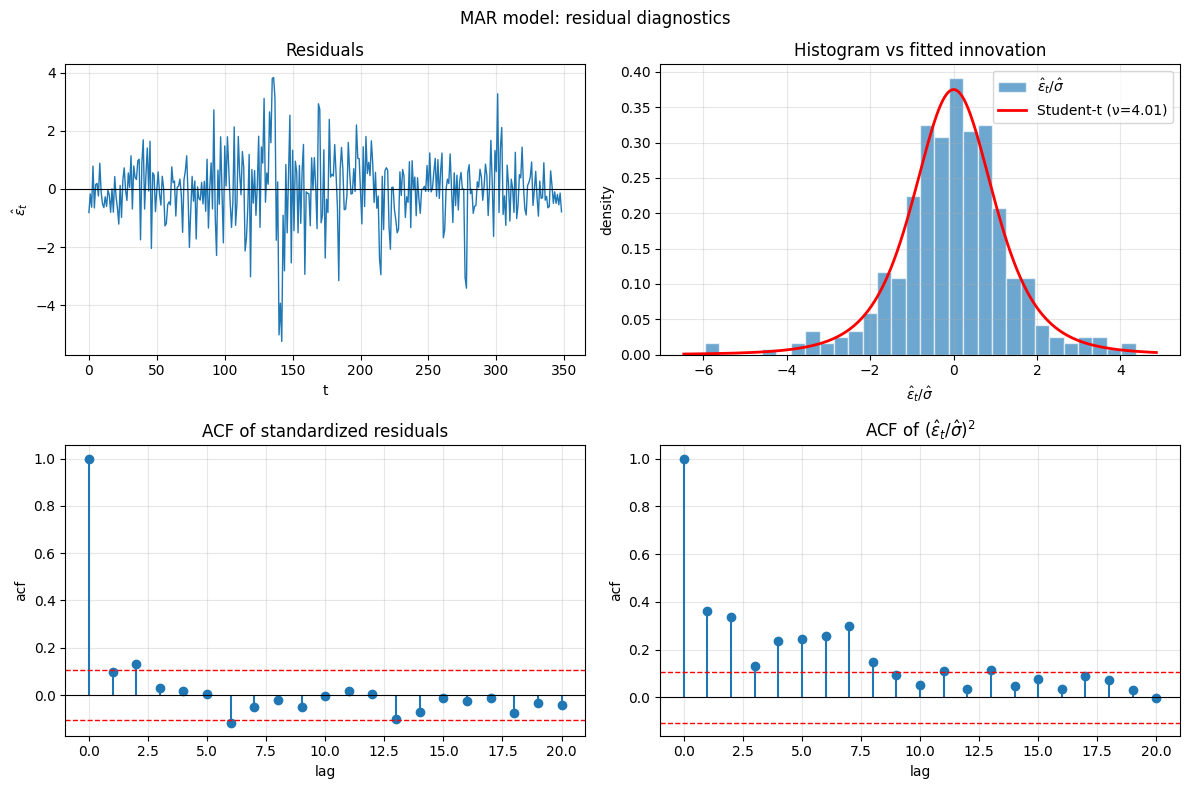

In [54]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

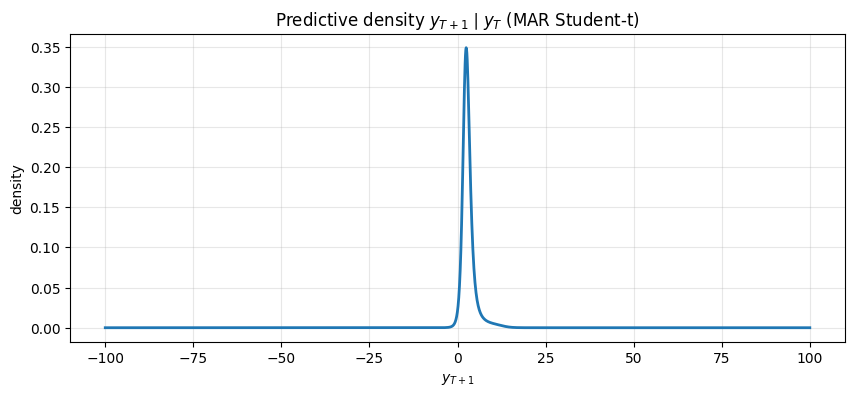

In [55]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

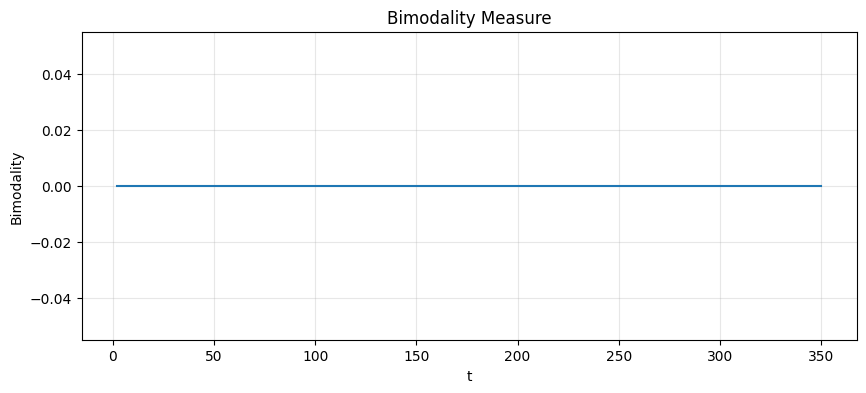

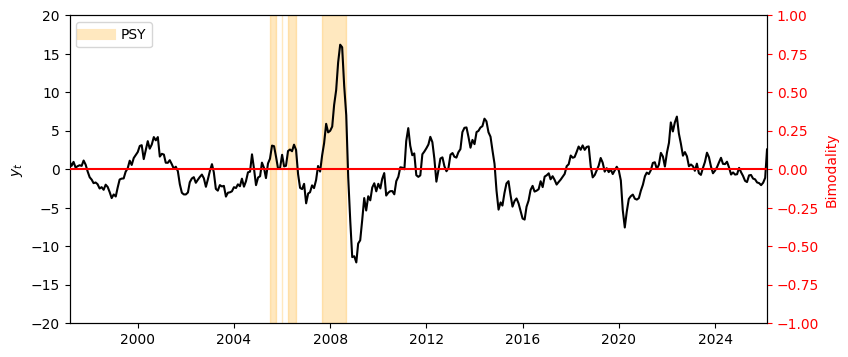

In [56]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -501.41582845319226

Estimated parameters:
phi             =     0.4356 (0.0668)
psi             =     0.5721 (0.0564)
beta_sp500      =    -0.0406 (0.0218)
beta_usd_ind    =    -0.0326 (0.0272)
beta_vix        =    -0.0844 (0.0458)
beta_epu        =    -0.0295 (0.0418)
beta_indpro     =     0.0695 (0.0201)
beta_fedfunds   =     0.0051 (0.0090)
beta_ngas_cycle =     0.2158 (0.0548)
beta_treasury_10y =     0.0803 (0.0305)
beta_oil_prod   =    -0.0079 (0.0626)
beta_world_oil_cycle =    -0.1611 (0.0356)
beta_crudeoil_inventory =    -0.1000 (0.0295)
beta_gpr        =     0.0507 (0.0274)
sigma           =     0.8091 (0.0573)
nu              =     4.5573 (1.2266)

Hessian condition number:
57848.54946636122

Eigenvalues of Hessian:
[3.83960232e+04 9.30189794e+03 3.84806387e+03 2.21487454e+03
 2.03310007e+03 1.45957618e+03 1.30083325e+03 1.02400101e+03
 6.63733551e-01 1.32164209e+02 2.06217780e+02 8.38755543e+02
 6.64467008e+02 6.05204951e+02 4.21489

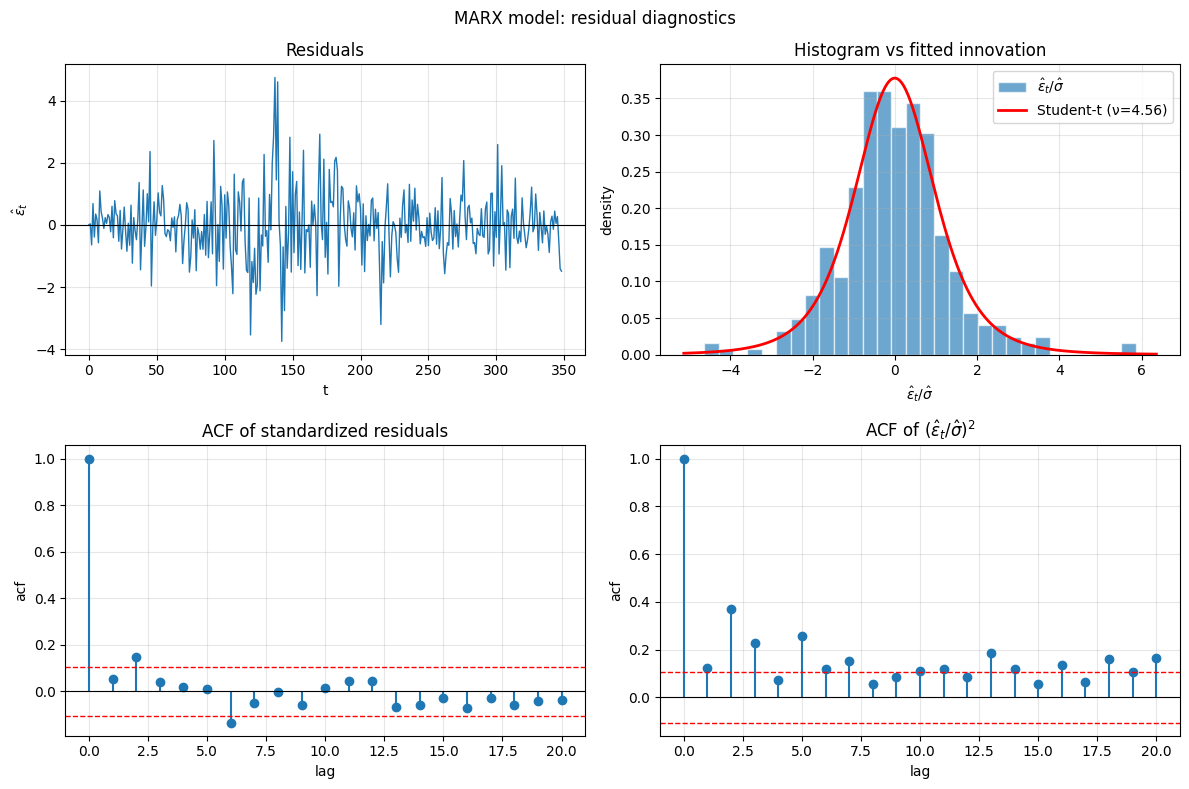

In [57]:
param_names = [ "phi", "psi", "beta_sp500", "beta_usd_ind", "beta_vix", "beta_epu", "beta_indpro", "beta_fedfunds", "beta_ngas_cycle", "beta_treasury_10y",  "beta_oil_prod", "beta_world_oil_cycle", "beta_crudeoil_inventory", "beta_gpr", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

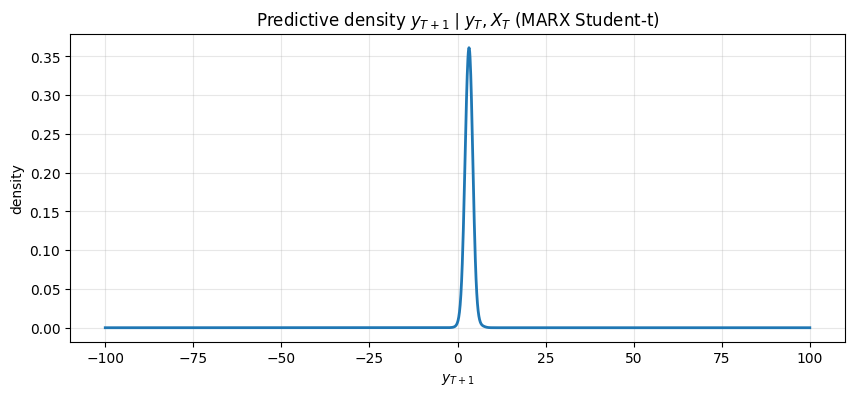

In [58]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

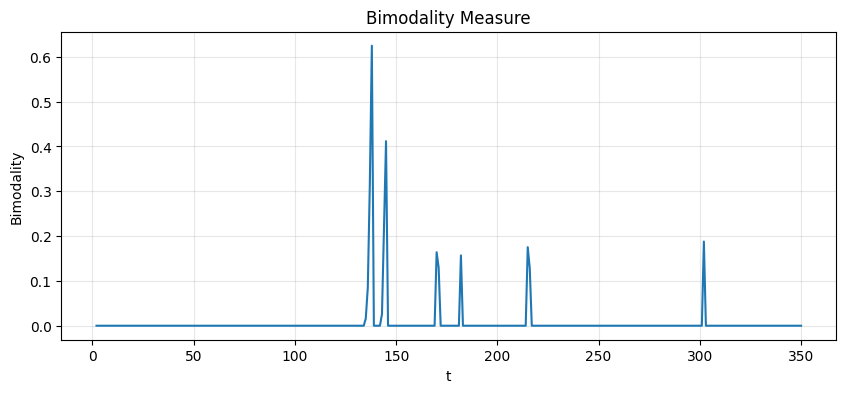

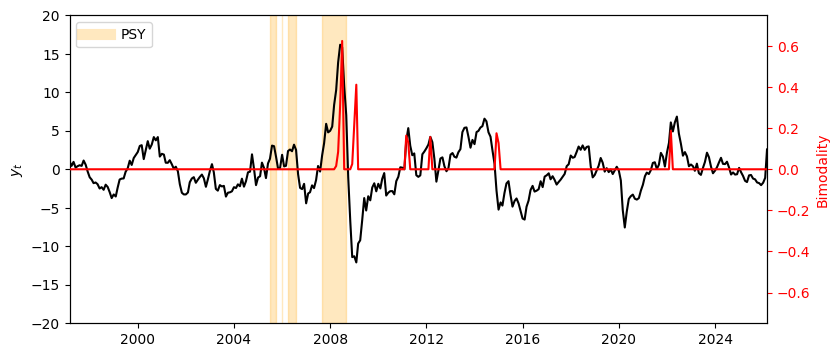

In [59]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)
